# Project info
Link to paper: https://kdd.org/exploration_files/p20-Is_Less_Really_More.pdf \
Link to authors' github repo: https://github.com/kappakant/SLIM/tree/main

# Imports

In [ ]:
import pandas as pd

# Preprocessing
The authors' repository and paper don't show specifically how they split the data, and they work based off of loaded csv's that aren't anywhere in the repository and seem to have come from their computer or another source that can't be identified. Therefore, to make sure we are following their preprocessing, we simply loaded their train, test, and validation csv's for both datasets.

Aside from this, the only other preprocessing the paper states is converting all text to lowercase and removing paragraph separators '\n'.

In [ ]:
# Load the datasets

base_url = "https://raw.githubusercontent.com/kappakant/SLIM/main/dataset"

files = {
    "ReCOVery": {
        "train": f"{base_url}/ReCOVery/train_preprocessed.csv",
        "validation": f"{base_url}/ReCOVery/eval_preprocessed.csv",
        "test": f"{base_url}/ReCOVery/test_preprocessed.csv",
    },
    "Fake_And_Real_News": {
        "train": f"{base_url}/fake_and_real_news/train_preprocessed.csv",
        "validation": f"{base_url}/fake_and_real_news/eval_preprocessed.csv",
        "test": f"{base_url}/fake_and_real_news/test_preprocessed.csv",
    }
}

for dataset, paths in files.items():
  print(f"Dataset: {dataset}")
  for split, path in paths.items():
      print(f"Split: {split}")
      display(pd.read_csv(path).head())

Dataset: ReCOVery
Split: train


,text,label
0,A novel respiratory virus that originated in W...,1
1,Chinese Health Officials: More Die From Newly ...,1
2,Public health experts around the globe are scr...,1
3,The first two coronavirus cases in Europe have...,0
4,"A new coronavirus appeared in Wuhan, China, at...",1


Split: validation


,text,label
0,Article courtesy of: Carol Petersen RPh CNP I...,0
1,Becoming the world's most advanced and largest...,0
2,Coronavirus Is Making It Even Harder For The C...,1
3,Instagram is attempting to stop the spread of ...,1
4,As the coronavirus pandemic continues to worse...,1


Split: test


,text,label
0,BEIJING — China on Tuesday reported 25 more de...,1
1,"Influenza is caused by a virus, and there are ...",0
2,Some agencies are reporting that officials in ...,0
3,Coronavirus Whistleblower Dies From The Diseas...,1
4,"Article courtesy of: Carol Petersen, RPh, CNP ...",0


... (2 outputs left out)

Split: validation


,label,merged_info
0,0,US Military Prepares To Shut Down Russia’s Int...
1,1,As Republican presidential candidates invoke S...
2,0,Welcome to the Trump World Order By Maria Dub...
3,1,"Killing Obama administration rules, dismantlin..."
4,1,5 Reasons (And Then Some) Not To Worry About A...


Split: test


,label,merged_info
0,0,opednews.com - Advertisement - The news in the...
1,0,October Boomerang ‹ › David Swanson is an auth...
2,0,David Frum: Hillary is a Patriot Who Will Prot...
3,0,By Reuters 5:51 pm Democratic nominee Hillar...
4,1,Brace Yourself: The Presidential Election Is G...


In [ ]:
# Basic preprocessing

def preprocess_text(text):
    return str(text).replace("\n", " ").lower() # replace "\n" with " " because otherwise words would be merged on newlines

# Since ReCOVery and Fake_And_Real_News have different column names for their main text components ("text" vs. "merged_info"), I renamed both columns to "body" to make it simpler to work with.
def preprocess_recovery(path):
    df = pd.read_csv(path)
    df["text"] = df["text"].apply(preprocess_text)
    df = df.rename(columns={"text": "body"})
    df = df[["label", "body"]] # switch the order of the columns to be label, body so that both datasets are consistent with order
    return df

def preprocess_fake_and_real(path):
    df = pd.read_csv(path)
    df["merged_info"] = df["merged_info"].apply(preprocess_text)
    df = df.rename(columns={"merged_info": "body"})
    return df

preprocessed = {
    "ReCOVery": {
        "train": preprocess_recovery(files["ReCOVery"]["train"]),
        "validation": preprocess_recovery(files["ReCOVery"]["validation"]),
        "test": preprocess_recovery(files["ReCOVery"]["test"]),
    },
    "Fake_And_Real_News": {
        "train": preprocess_fake_and_real(files["Fake_And_Real_News"]["train"]),
        "validation": preprocess_fake_and_real(files["Fake_And_Real_News"]["validation"]),
        "test": preprocess_fake_and_real(files["Fake_And_Real_News"]["test"]),
    }
}

def display_preprocessed_data():
  for dataset, splits in preprocessed.items():
    print("=" * 20)
    print(f"Dataset: {dataset}")
    for split, df in splits.items():
        print("-" * 20)
        print(f"Split: {split}")
        display(df.head())

display_preprocessed_data()

Dataset: ReCOVery
--------------------
Split: train


,label,body
0,1,a novel respiratory virus that originated in w...
1,1,chinese health officials: more die from newly ...
2,1,public health experts around the globe are scr...
3,0,the first two coronavirus cases in europe have...
4,1,"a new coronavirus appeared in wuhan, china, at..."


--------------------
Split: validation


,label,body
0,0,article courtesy of: carol petersen rph cnp i...
1,0,becoming the world's most advanced and largest...
2,1,coronavirus is making it even harder for the c...
3,1,instagram is attempting to stop the spread of ...
4,1,as the coronavirus pandemic continues to worse...


--------------------
Split: test


,label,body
0,1,beijing — china on tuesday reported 25 more de...
1,0,"influenza is caused by a virus, and there are ..."
2,0,some agencies are reporting that officials in ...
3,1,coronavirus whistleblower dies from the diseas...
4,0,"article courtesy of: carol petersen, rph, cnp ..."


... (2 outputs left out)

--------------------
Split: validation


,label,body
0,0,us military prepares to shut down russia’s int...
1,1,as republican presidential candidates invoke s...
2,0,welcome to the trump world order by maria dub...
3,1,"killing obama administration rules, dismantlin..."
4,1,5 reasons (and then some) not to worry about a...


--------------------
Split: test


,label,body
0,0,opednews.com - advertisement - the news in the...
1,0,october boomerang ‹ › david swanson is an auth...
2,0,david frum: hillary is a patriot who will prot...
3,0,by reuters 5:51 pm democratic nominee hillar...
4,1,brace yourself: the presidential election is g...


In [ ]:
# Other checks

for dataset, splits in preprocessed.items():
  print("=" * 20)
  print(f"Dataset: {dataset}")

  for split, df in splits.items():
      print("-" * 20)
      print(f"Split: {split}")
      print("Rows:", len(df))
      print("Missing text:", df["body"].isna().sum())
      print("Duplicate articles:", df["body"].duplicated().sum())
      print("Label counts:")
      print(df["label"].value_counts().sort_index())



Dataset: ReCOVery
--------------------
Split: train
Rows: 1453
Missing text: 0
Duplicate articles: 83
Label counts:
label
0    487
1    966
Name: count, dtype: int64
--------------------
Split: validation
Rows: 184
Missing text: 0
Duplicate articles: 4
Label counts:
label
0     64
1    120
Name: count, dtype: int64
--------------------
Split: test
Rows: 392
Missing text: 0
Duplicate articles: 16
Label counts:
label
0    114
1    278
Name: count, dtype: int64
Dataset: Fake_And_Real_News
--------------------
Split: train
Rows: 2297
Missing text: 0
Duplicate articles: 81
Label counts:
label
0    1154
1    1143
Name: count, dtype: int64
--------------------
Split: validation
Rows: 1148
Missing text: 0
Duplicate articles: 37
Label counts:
label
0    551
1    597
Name: count, dtype: int64
--------------------
Split: test
Rows: 1149
Missing text: 0
Duplicate articles: 27
Label counts:
label
0    592
1    557
Name: count, dtype: int64


There are no missing values. Although there are some duplicate news articles, we do not remove them (or take any further preprocessing steps in general) because the authors did not say they did so. This is only for our own insight about the datasets.

IMPORTANT: The validation and test splits are swapped in the authors' code vs. what it is written in their paper, e.g. the paper says ReCOVery validation is 114 / 278 and test is 64 / 120 while the code is the other way around, as shown in the results above. We chose to follow what the code does.

# Baseline Model and Evaluation

The baseline model uses the complete article body as input.

Following the paper, XLNet-base is fine-tuned for fake-news classification. The model uses cross-entropy loss for classification and the Adam optimizer with a learning rate of 5 × 10^-5.

The model is evaluated using accuracy, macro-F1, and AUC on the validation and test sets.

In [ ]:
!pip install -q transformers sentencepiece accelerate

In [ ]:
import copy
import random
import numpy as np
import pandas as pd
import torch

from torch.utils.data import Dataset, DataLoader

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

from sklearn.preprocessing import LabelEncoder

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

In [ ]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

MODEL_NAME = "xlnet-base-cased"
MAX_LENGTH = 512
BATCH_SIZE = 16
EPOCHS = 8
LEARNING_RATE = 2e-5

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

Using device: cuda


In [ ]:
def prepare_dataset(dataset_name):
    train_df = preprocessed[dataset_name]["train"].copy()
    validation_df = preprocessed[dataset_name]["validation"].copy()
    test_df = preprocessed[dataset_name]["test"].copy()

    return train_df, validation_df, test_df


recovery_train, recovery_val, recovery_test = prepare_dataset(
    "ReCOVery"
)

fake_train, fake_val, fake_test = prepare_dataset(
    "Fake_And_Real_News"
)

In [ ]:
def encode_labels(train_df, validation_df, test_df):
    label_encoder = LabelEncoder()

    train_df = train_df.copy()
    validation_df = validation_df.copy()
    test_df = test_df.copy()

    train_df["label_encoded"] = label_encoder.fit_transform(
        train_df["label"]
    )

    validation_df["label_encoded"] = label_encoder.transform(
        validation_df["label"]
    )

    test_df["label_encoded"] = label_encoder.transform(
        test_df["label"]
    )

    return (
        train_df,
        validation_df,
        test_df,
        label_encoder
    )

In [ ]:
(
    recovery_train,
    recovery_val,
    recovery_test,
    recovery_label_encoder
) = encode_labels(
    recovery_train,
    recovery_val,
    recovery_test
)

(
    fake_train,
    fake_val,
    fake_test,
    fake_label_encoder
) = encode_labels(
    fake_train,
    fake_val,
    fake_test
)

print(
    "ReCOVery label mapping:",
    dict(
        zip(
            recovery_label_encoder.classes_,
            recovery_label_encoder.transform(
                recovery_label_encoder.classes_
            )
        )
    )
)

print(
    "Fake_And_Real_News label mapping:",
    dict(
        zip(
            fake_label_encoder.classes_,
            fake_label_encoder.transform(
                fake_label_encoder.classes_
            )
        )
    )
)

ReCOVery label mapping: {np.int64(0): np.int64(0), np.int64(1): np.int64(1)}
Fake_And_Real_News label mapping: {np.int64(0): np.int64(0), np.int64(1): np.int64(1)}


In [ ]:
class NewsDataset(Dataset):
    def __init__(self, dataframe):
        self.texts = dataframe["body"].astype(str).tolist()
        self.labels = dataframe["label_encoded"].tolist()

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, index):
        return {
            "text": self.texts[index],
            "labels": self.labels[index]
        }

In [ ]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)


def create_dataloader(dataframe, shuffle=False):
    dataset = NewsDataset(dataframe)

    def collate_batch(batch):
        texts = [
            item["text"]
            for item in batch
        ]

        labels = torch.tensor(
            [
                item["labels"]
                for item in batch
            ],
            dtype=torch.long
        )

        encoded = tokenizer(
            texts,
            padding=True,
            truncation=True,
            max_length=MAX_LENGTH,
            return_tensors="pt"
        )

        encoded["labels"] = labels

        return encoded

    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        collate_fn=collate_batch
    )

In [ ]:
def evaluate_xlnet(
    model,
    data_loader,
    dataset_name,
    split_name,
    model_name
):
    model.eval()

    all_labels = []
    all_predictions = []
    all_probabilities = []

    with torch.no_grad():
        for batch in data_loader:
            batch = {
                key: value.to(device)
                for key, value in batch.items()
            }

            labels = batch["labels"]

            outputs = model(**batch)

            probabilities = torch.softmax(
                outputs.logits,
                dim=1
            )

            predictions = torch.argmax(
                probabilities,
                dim=1
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_probabilities.extend(
                probabilities[:, 1].cpu().numpy()
            )

    accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro"
    )

    auc = roc_auc_score(
        all_labels,
        all_probabilities
    )

    print(
        f"\n{dataset_name} - "
        f"{model_name} - "
        f"{split_name}"
    )

    print("-" * 60)
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Macro-F1: {macro_f1:.4f}")
    print(f"AUC: {auc:.4f}")

    print("\nClassification Report:")
    print(
        classification_report(
            all_labels,
            all_predictions
        )
    )

    return {
        "dataset": dataset_name,
        "model": model_name,
        "split": split_name,
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "auc": auc,
        "labels": all_labels,
        "predictions": all_predictions,
        "probabilities": all_probabilities
    }

In [ ]:
def train_xlnet_baseline(
    train_df,
    validation_df,
    test_df,
    dataset_name,
    epochs=EPOCHS,
    learning_rate=LEARNING_RATE,
    model_name="XLNet Full-Text Baseline"
):
    train_loader = create_dataloader(
        train_df,
        shuffle=True
    )

    validation_loader = create_dataloader(
        validation_df,
        shuffle=False
    )

    test_loader = create_dataloader(
        test_df,
        shuffle=False
    )

    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME,
        num_labels=2
    )

    model.to(device)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=learning_rate
    )

    best_validation_f1 = -1
    best_model_state = None

    for epoch in range(epochs):
        model.train()
        total_training_loss = 0

        for batch in train_loader:
            batch = {
                key: value.to(device)
                for key, value in batch.items()
            }

            optimizer.zero_grad()

            outputs = model(**batch)

            # XLNet returns cross-entropy loss
            loss = outputs.loss

            loss.backward()
            optimizer.step()

            total_training_loss += loss.item()

        average_training_loss = (
            total_training_loss / len(train_loader)
        )

        validation_results = evaluate_xlnet(
            model=model,
            data_loader=validation_loader,
            dataset_name=dataset_name,
            split_name=f"Validation - Epoch {epoch + 1}",
            model_name=model_name
        )

        print(
            f"Average training loss: "
            f"{average_training_loss:.4f}"
        )

        if (
            validation_results["macro_f1"]
            > best_validation_f1
        ):
            best_validation_f1 = (
                validation_results["macro_f1"]
            )

            best_model_state = copy.deepcopy(
                model.state_dict()
            )

    model.load_state_dict(best_model_state)

    final_validation_results = evaluate_xlnet(
        model=model,
        data_loader=validation_loader,
        dataset_name=dataset_name,
        split_name="Validation - Best Model",
        model_name=model_name
    )

    test_results = evaluate_xlnet(
        model=model,
        data_loader=test_loader,
        dataset_name=dataset_name,
        split_name="Test",
        model_name=model_name
    )

    return {
        "model": model,
        "tokenizer": tokenizer,
        "validation_results": final_validation_results,
        "test_results": test_results
    }

In [ ]:
recovery_baseline = train_xlnet_baseline(
    recovery_train,
    recovery_val,
    recovery_test,
    "ReCOVery"
)

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  467MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  467MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/206 [00:00<?, ?it/s]

[transformers] XLNetForSequenceClassification LOAD REPORT from: xlnet-base-cased
Key                             | Status     | 
--------------------------------+------------+-
lm_loss.weight                  | UNEXPECTED | 
lm_loss.bias                    | UNEXPECTED | 
logits_proj.weight              | MISSING    | 
logits_proj.bias                | MISSING    | 
sequence_summary.summary.weight | MISSING    | 
sequence_summary.summary.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


... (6 outputs left out)


ReCOVery - XLNet Full-Text Baseline - Validation - Best Model
------------------------------------------------------------
Accuracy: 0.6522
Macro-F1: 0.3947
AUC: 0.7227

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00        64
           1       0.65      1.00      0.79       120

    accuracy                           0.65       184
   macro avg       0.33      0.50      0.39       184
weighted avg       0.43      0.65      0.51       184



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



ReCOVery - XLNet Full-Text Baseline - Test
------------------------------------------------------------
Accuracy: 0.7092
Macro-F1: 0.4149
AUC: 0.7479

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00       114
           1       0.71      1.00      0.83       278

    accuracy                           0.71       392
   macro avg       0.35      0.50      0.41       392
weighted avg       0.50      0.71      0.59       392



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
fake_real_baseline = train_xlnet_baseline(
    fake_train,
    fake_val,
    fake_test,
    "Fake_And_Real_News"
)

Loading weights:   0%|          | 0/206 [00:00<?, ?it/s]

[transformers] XLNetForSequenceClassification LOAD REPORT from: xlnet-base-cased
Key                             | Status     | 
--------------------------------+------------+-
lm_loss.weight                  | UNEXPECTED | 
lm_loss.bias                    | UNEXPECTED | 
logits_proj.weight              | MISSING    | 
logits_proj.bias                | MISSING    | 
sequence_summary.summary.weight | MISSING    | 
sequence_summary.summary.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



Fake_And_Real_News - XLNet Full-Text Baseline - Validation - Epoch 1
------------------------------------------------------------
Accuracy: 0.9216
Macro-F1: 0.9216
AUC: 0.9823

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.97      0.92       551
           1       0.97      0.88      0.92       597

    accuracy                           0.92      1148
   macro avg       0.92      0.92      0.92      1148
weighted avg       0.93      0.92      0.92      1148

Average training loss: 0.3711

Fake_And_Real_News - XLNet Full-Text Baseline - Validation - Epoch 2
------------------------------------------------------------
Accuracy: 0.9129
Macro-F1: 0.9129
AUC: 0.9831

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.96      0.91       551
           1       0.96      0.87      0.91       597

    accuracy                           0.91      1148
   macro avg       0.92

In [ ]:
baseline_results = pd.DataFrame([
    recovery_baseline["validation_results"],
    recovery_baseline["test_results"],
    fake_real_baseline["validation_results"],
    fake_real_baseline["test_results"]
])

baseline_results[
    [
        "dataset",
        "model",
        "split",
        "accuracy",
        "macro_f1",
        "auc"
    ]
]

,dataset,model,split,accuracy,macro_f1,auc
0,ReCOVery,XLNet Full-Text Baseline,Validation - Best Model,0.652174,0.394737,0.722656
1,ReCOVery,XLNet Full-Text Baseline,Test,0.709184,0.414925,0.747933
2,Fake_And_Real_News,XLNet Full-Text Baseline,Validation - Best Model,0.923345,0.923322,0.966692
3,Fake_And_Real_News,XLNet Full-Text Baseline,Test,0.932115,0.931628,0.961531


In [ ]:
def display_xlnet_confusion_matrix(
    results,
    dataset_name
):
    labels = results["labels"]
    predictions = results["predictions"]

    matrix = confusion_matrix(
        labels,
        predictions
    )

    display_plot = ConfusionMatrixDisplay(
        confusion_matrix=matrix
    )

    display_plot.plot(cmap="Blues")

    plt.title(
        f"{dataset_name} - XLNet Baseline"
    )

    plt.show()

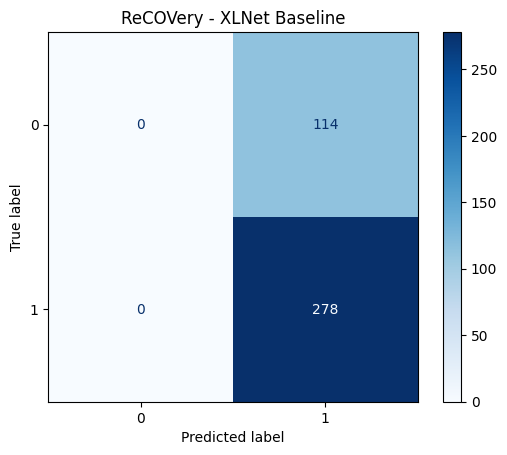

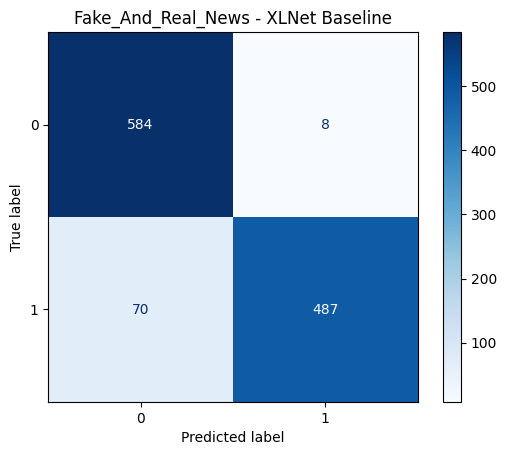

In [ ]:
display_xlnet_confusion_matrix(
    recovery_baseline["test_results"],
    "ReCOVery"
)

display_xlnet_confusion_matrix(
    fake_real_baseline["test_results"],
    "Fake_And_Real_News"
)

# SLIM Keyword

This experiment follows the paper's keyword-based SLIM method. BERT embeddings are created for the complete document and individual words. Words with positive cosine similarity to the document are retained, and Maximal Marginal Relevance (MMR) selects relevant but non-redundant keywords.

The selected keywords are then classified using the same XLNet pipeline as the full-text baseline.

In [ ]:
!pip install -q transformers sentencepiece

In [ ]:
import re
import math
import numpy as np
import torch

from transformers import (
    AutoTokenizer,
    AutoModel
)

from sklearn.metrics.pairwise import cosine_similarity

In [ ]:
BERT_MODEL_NAME = "bert-base-uncased"
BERT_MAX_LENGTH = 512

bert_tokenizer = AutoTokenizer.from_pretrained(
    BERT_MODEL_NAME
)

bert_encoder = AutoModel.from_pretrained(
    BERT_MODEL_NAME
)

bert_encoder = bert_encoder.to(device)
bert_encoder.eval()

print("Keyword encoder:", BERT_MODEL_NAME)
print("Keyword encoder device:", device)

In [ ]:
def mean_pool_embeddings(
    model_output,
    attention_mask
):
    token_embeddings = model_output.last_hidden_state

    expanded_mask = attention_mask.unsqueeze(-1).expand(
        token_embeddings.size()
    ).float()

    summed_embeddings = torch.sum(
        token_embeddings * expanded_mask,
        dim=1
    )

    number_of_tokens = torch.clamp(
        expanded_mask.sum(dim=1),
        min=1e-9
    )

    return summed_embeddings / number_of_tokens

In [ ]:
def encode_with_bert(
    texts,
    batch_size=16
):
    all_embeddings = []

    for start_index in range(
        0,
        len(texts),
        batch_size
    ):
        batch_texts = texts[
            start_index:start_index + batch_size
        ]

        encoded = bert_tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=BERT_MAX_LENGTH,
            return_tensors="pt"
        )

        encoded = {
            key: value.to(device)
            for key, value in encoded.items()
        }

        with torch.no_grad():
            model_output = bert_encoder(
                **encoded
            )

        embeddings = mean_pool_embeddings(
            model_output,
            encoded["attention_mask"]
        )

        all_embeddings.append(
            embeddings.cpu().numpy()
        )

    return np.vstack(all_embeddings)

In [ ]:
word_embedding_cache = {}


def get_word_embeddings(words):
    missing_words = [
        word
        for word in words
        if word not in word_embedding_cache
    ]

    if len(missing_words) > 0:
        missing_embeddings = encode_with_bert(
            missing_words,
            batch_size=32
        )

        for word, embedding in zip(
            missing_words,
            missing_embeddings
        ):
            word_embedding_cache[word] = embedding

    return np.vstack([
        word_embedding_cache[word]
        for word in words
    ])

In [ ]:
def extract_slim_keywords(
    text,
    percentage=0.30,
    lambda_mmr=0.5
):
    text = str(text)

    words = re.findall(
        r"[A-Za-z]+(?:'[A-Za-z]+)?",
        text
    )

    if len(words) == 0:
        return ""

    unique_words = list(
        dict.fromkeys(words)
    )

    requested_count = max(
        1,
        math.floor(
            len(words) * percentage
        )
    )

    requested_count = min(
        requested_count,
        len(unique_words)
    )

    document_embedding = encode_with_bert(
        [text],
        batch_size=1
    )[0]

    word_embeddings = get_word_embeddings(
        unique_words
    )

    relevance_scores = cosine_similarity(
        word_embeddings,
        document_embedding.reshape(1, -1)
    ).reshape(-1)

    # The paper retains words with positive cosine similarity
    candidate_indices = [
        index
        for index, score in enumerate(
            relevance_scores
        )
        if score > 0
    ]

    # Fallback in case no word has positive similarity
    if len(candidate_indices) == 0:
        candidate_indices = list(
            np.argsort(
                relevance_scores
            )[::-1]
        )

    selected_indices = []

    while (
        len(selected_indices) < requested_count
        and len(candidate_indices) > 0
    ):
        mmr_scores = []

        for candidate_index in candidate_indices:
            relevance = relevance_scores[
                candidate_index
            ]

            if len(selected_indices) == 0:
                redundancy = 0

            else:
                selected_embeddings = (
                    word_embeddings[selected_indices]
                )

                candidate_embedding = (
                    word_embeddings[
                        candidate_index
                    ].reshape(1, -1)
                )

                similarities_to_selected = (
                    cosine_similarity(
                        candidate_embedding,
                        selected_embeddings
                    ).reshape(-1)
                )

                redundancy = np.max(
                    similarities_to_selected
                )

            # MMR:
            # lambda * relevance
            # - (1 - lambda) * redundancy
            mmr_score = (
                lambda_mmr * relevance
                - (1 - lambda_mmr) * redundancy
            )

            mmr_scores.append(
                (candidate_index, mmr_score)
            )

        best_index, best_score = max(
            mmr_scores,
            key=lambda item: item[1]
        )

        selected_indices.append(best_index)
        candidate_indices.remove(best_index)

    selected_keywords = [
        unique_words[index]
        for index in selected_indices
    ]

    return " ".join(selected_keywords)

In [ ]:
example_article = preprocessed[
    "ReCOVery"
]["train"].iloc[0]["body"]

selected_keywords = extract_slim_keywords(
    example_article,
    percentage=0.30,
    lambda_mmr=0.5
)

print("Original article:")
print(example_article[:1000])

print("\nSelected keywords:")
print(selected_keywords)

In [ ]:
KEYWORD_PERCENTAGE = 0.30
MMR_LAMBDA = 0.5

print(
    "Keyword percentage:",
    KEYWORD_PERCENTAGE * 100,
    "%"
)

print(
    "MMR lambda:",
    MMR_LAMBDA
)

In [ ]:
def create_keyword_dataset(
    dataset_name,
    percentage,
    lambda_mmr
):
    keyword_data = {}

    for split, dataframe in preprocessed[
        dataset_name
    ].items():

        print(
            f"Extracting keywords: "
            f"{dataset_name} - {split}"
        )

        keyword_dataframe = dataframe.copy()

        keyword_dataframe["body"] = (
            keyword_dataframe["body"].apply(
                lambda text: extract_slim_keywords(
                    text,
                    percentage=percentage,
                    lambda_mmr=lambda_mmr
                )
            )
        )

        keyword_data[split] = (
            keyword_dataframe[
                ["label", "body"]
            ].copy()
        )

    return keyword_data

In [ ]:
recovery_keyword_data = create_keyword_dataset(
    dataset_name="ReCOVery",
    percentage=KEYWORD_PERCENTAGE,
    lambda_mmr=MMR_LAMBDA
)

In [ ]:
fake_real_keyword_data = create_keyword_dataset(
    dataset_name="Fake_And_Real_News",
    percentage=KEYWORD_PERCENTAGE,
    lambda_mmr=MMR_LAMBDA
)

In [ ]:
display(
    recovery_keyword_data["train"].head()
)

display(
    fake_real_keyword_data["train"].head()
)

In [ ]:
def compare_keyword_reduction(
    dataset_name,
    keyword_data,
    split_name="test"
):
    original_word_counts = (
        preprocessed[dataset_name][split_name]["body"]
        .str.split()
        .str.len()
    )

    keyword_word_counts = (
        keyword_data[split_name]["body"]
        .str.split()
        .str.len()
    )

    average_original = (
        original_word_counts.mean()
    )

    average_keywords = (
        keyword_word_counts.mean()
    )

    percentage_retained = (
        average_keywords
        / average_original
        * 100
    )

    print(dataset_name)
    print(
        "Average original words:",
        round(average_original, 2)
    )

    print(
        "Average selected keywords:",
        round(average_keywords, 2)
    )

    print(
        "Percentage retained:",
        round(percentage_retained, 2),
        "%"
    )

In [ ]:
compare_keyword_reduction(
    "ReCOVery",
    recovery_keyword_data
)

compare_keyword_reduction(
    "Fake_And_Real_News",
    fake_real_keyword_data
)

In [ ]:
(
    recovery_keyword_train,
    recovery_keyword_val,
    recovery_keyword_test,
    recovery_keyword_label_encoder
) = encode_labels(
    recovery_keyword_data["train"],
    recovery_keyword_data["validation"],
    recovery_keyword_data["test"]
)

(
    fake_real_keyword_train,
    fake_real_keyword_val,
    fake_real_keyword_test,
    fake_real_keyword_label_encoder
) = encode_labels(
    fake_real_keyword_data["train"],
    fake_real_keyword_data["validation"],
    fake_real_keyword_data["test"]
)

In [ ]:
recovery_keyword_results = train_xlnet_baseline(
    recovery_keyword_train,
    recovery_keyword_val,
    recovery_keyword_test,
    "ReCOVery",
    epochs=EPOCHS,
    learning_rate=LEARNING_RATE,
    model_name="ReCOVery SLIM Keyword"
)

In [ ]:
fake_real_keyword_results = train_xlnet_baseline(
    fake_real_keyword_train,
    fake_real_keyword_val,
    fake_real_keyword_test,
    "Fake_And_Real_News",
    epochs=EPOCHS,
    learning_rate=LEARNING_RATE,
    model_name="Fake_And_Real_News SLIM Keyword"
)

In [ ]:
keyword_results = pd.DataFrame([
    recovery_baseline["test_results"],
    recovery_keyword_results["test_results"],
    fake_real_baseline["test_results"],
    fake_real_keyword_results["test_results"]
])

keyword_results[
    [
        "dataset",
        "model",
        "split",
        "accuracy",
        "macro_f1",
        "auc"
    ]
]

# SLIM Metadata

Attaching the metadata to the authors' preprocessed csv's

In [ ]:
recovery_url = "https://raw.githubusercontent.com/apurvamulay/ReCOVery/master/dataset/recovery-news-data.csv"
recovery_original = pd.read_csv(recovery_url)

fake_real_url = "https://raw.githubusercontent.com/GeorgeMcIntire/fake_real_news_dataset/main/fake_and_real_news_dataset.csv"
fake_real_original = pd.read_csv(fake_real_url)

display(recovery_original.head())
display(fake_real_original.head())

,Unnamed: 0,news_id,url,publisher,publish_date,author,title,image,body_text,political_bias,country,reliability
0,0,0,https://www.nytimes.com/article/what-is-corona...,The New York Times,2020-01-21,"['Knvul Sheikh', 'Roni Caryn Rabin']",The Coronavirus: What Scientists Have Learned ...,https://static01.nyt.com/images/2020/03/12/sci...,\nA novel respiratory virus that originated in...,Left,USA,1
1,1,1,https://www.npr.org/2020/01/22/798392172/chine...,National Public Radio (NPR),2020-01-22,['Emily Feng'],Chinese Health Officials: More Die From Newly ...,https://media.npr.org/include/images/facebook-...,Chinese Health Officials: More Die From Newly ...,Center,USA,1
2,2,2,https://www.theverge.com/2020/1/23/21078457/co...,The Verge,2020-01-23,['Nicole Wetsman'],Everything you need to know about the coronavirus,https://cdn.vox-cdn.com/thumbor/a9_Oz7cvSBKyal...,Public health experts around the globe are scr...,Left-center,USA,1
3,3,3,https://www.worldhealth.net/news/novel-coronav...,WorldHealth.Net,2020-01-24,[],Novel Coronavirus Cases Confirmed To Be Spreading,https://www.worldhealth.net/media/original_ima...,The first two coronavirus cases in Europe have...,NaN,USA,0
4,4,4,https://www.theverge.com/2020/1/24/21080845/co...,The Verge,2020-01-24,"['Nicole Wetsman', 'Zoe Schiffer', 'Jay Peters...",Coronavirus disrupts the world: updates on the...,https://cdn.vox-cdn.com/thumbor/t2gt1SmEni4Mcr...,"A new coronavirus appeared in Wuhan, China, at...",Left-center,USA,1


,idd,title,text,label
0,Fq+C96tcx+,‘A target on Roe v. Wade ’: Oklahoma bill maki...,UPDATE: Gov. Fallin vetoed the bill on Friday....,REAL
1,bHUqK!pgmv,Study: women had to drive 4 times farther afte...,Ever since Texas laws closed about half of the...,REAL
2,4Y4Ubf%aTi,"Trump, Clinton clash in dueling DC speeches","Donald Trump and Hillary Clinton, now at the s...",REAL
3,_CoY89SJ@K,Grand jury in Texas indicts activists behind P...,A Houston grand jury investigating criminal al...,REAL
4,+rJHoRQVLe,"As Reproductive Rights Hang In The Balance, De...",WASHINGTON -- Forty-three years after the Supr...,REAL


In [ ]:
print("========== ReCOVery ==========")
print("Columns:", recovery_original.columns.tolist())
print("Shape:", recovery_original.shape)
print("Missing values:")
print(recovery_original[["body_text", "title", "author", "reliability"]].isna().sum())

print("\n========== Fake and Real News ==========")
print("Columns:", fake_real_original.columns.tolist())
print("Shape:", fake_real_original.shape)
print("Missing values:")
print(fake_real_original[["text", "title", "label"]].isna().sum())

========== ReCOVery ==========
Columns: ['Unnamed: 0', 'news_id', 'url', 'publisher', 'publish_date', 'author', 'title', 'image', 'body_text', 'political_bias', 'country', 'reliability']
Shape: (2029, 12)
Missing values:
body_text      0
title          3
author         1
reliability    0
dtype: int64

========== Fake and Real News ==========
Columns: ['idd', 'title', 'text', 'label']
Shape: (4594, 4)
Missing values:
text     0
title    1
label    0
dtype: int64


In [ ]:
# similar to preprocess_text
def preprocess_body(text):
  if pd.isna(text):
    return ""
  text = str(text).replace("\n", " ").lower()
  text = " ".join(text.split())
  return text

In [ ]:
# copies of the original for the purpose of matching the metadata

recovery_matching = recovery_original.copy()
fake_real_matching = fake_real_original.copy()

recovery_matching["body_key"] = recovery_matching["body_text"].apply(preprocess_body)
fake_real_matching["body_key"] = fake_real_matching["text"].apply(preprocess_body)

display(recovery_matching[["body_text", "body_key"]].head(3))
display(fake_real_matching[["text", "body_key"]].head(3))

,body_text,body_key
0,\nA novel respiratory virus that originated in...,a novel respiratory virus that originated in w...
1,Chinese Health Officials: More Die From Newly ...,chinese health officials: more die from newly ...
2,Public health experts around the globe are scr...,public health experts around the globe are scr...


,text,body_key
0,UPDATE: Gov. Fallin vetoed the bill on Friday....,update: gov. fallin vetoed the bill on friday....
1,Ever since Texas laws closed about half of the...,ever since texas laws closed about half of the...
2,"Donald Trump and Hillary Clinton, now at the s...","donald trump and hillary clinton, now at the s..."


In [ ]:
for name, df in [("ReCOVery", recovery_matching), ("Fake and Real News", fake_real_matching)]:
    print(f"\n========== {name} ==========")
    print("Total records:", len(df))
    print("Unique bodies:", df["body_key"].nunique())
    print("Duplicate body groups:", df["body_key"].duplicated(keep=False).sum())


print("\nUnique records for title metadata")
for name, df in [("ReCOVery", recovery_matching), ("Fake and Real News", fake_real_matching)]:
    title_counts = df.groupby("body_key")["title"].nunique()

    print(f"\n========== {name} ==========")
    print("Body groups with one title:", (title_counts == 1).sum())
    print("Body groups with multiple titles:", (title_counts > 1).sum())


print("\nUnique records for author metadata")
recovery_with_authors = recovery_matching[
    recovery_matching["author"].notna() &
    recovery_matching["author"].str.strip().ne("[]")]

author_counts = recovery_with_authors.groupby("body_key")["author"].nunique()

print(f"\n========== ReCOVery ==========")
print("Body groups with one author:", (author_counts == 1).sum())
print("Body groups with multiple authors:", (author_counts > 1).sum())


========== ReCOVery ==========
Total records: 2029
Unique bodies: 1910
Duplicate body groups: 143

========== Fake and Real News ==========
Total records: 4594
Unique bodies: 4408
Duplicate body groups: 230

Unique records for title metadata

========== ReCOVery ==========
Body groups with one title: 1885
Body groups with multiple titles: 23

========== Fake and Real News ==========
Body groups with one title: 4382
Body groups with multiple titles: 26

Unique records for author metadata

========== ReCOVery ==========
Body groups with one author: 1368
Body groups with multiple authors: 6


In [ ]:
# recovery title metadata recovery
# only keep records that have one unique title
recovery_title_counts = (
    recovery_matching
    .dropna(subset=["title"])
    .groupby("body_key")["title"]
    .nunique()
)

recovery_valid_title_keys = recovery_title_counts[recovery_title_counts == 1].index

# retrieve body keys that have one unique title, and drop duplicates and na values
recovery_title_lookup = (
    recovery_matching[
        recovery_matching["body_key"].isin(recovery_valid_title_keys)
        ][["body_key", "title"]]
        .dropna(subset=["title"])
        .drop_duplicates(subset=["body_key"])
        .copy()
)

print("Unique bodies with unambiguous titles:", len(recovery_title_lookup))
display(recovery_title_lookup.head())


Unique bodies with unambiguous titles: 1885


,body_key,title
0,a novel respiratory virus that originated in w...,The Coronavirus: What Scientists Have Learned ...
1,chinese health officials: more die from newly ...,Chinese Health Officials: More Die From Newly ...
2,public health experts around the globe are scr...,Everything you need to know about the coronavirus
3,the first two coronavirus cases in europe have...,Novel Coronavirus Cases Confirmed To Be Spreading
4,"a new coronavirus appeared in wuhan, china, at...",Coronavirus disrupts the world: updates on the...


In [ ]:
# fake and real title metadata recovery
# only keep records that have one unique title
fake_real_title_counts = (
    fake_real_matching
    .dropna(subset=["title"])
    .groupby("body_key")["title"]
    .nunique()
)

fake_real_valid_title_keys = fake_real_title_counts[fake_real_title_counts == 1].index

fake_real_title_lookup = (
    fake_real_matching[
        fake_real_matching["body_key"].isin(fake_real_valid_title_keys)
        ][["body_key", "title"]]
        .dropna(subset=["title"])
        .drop_duplicates(subset=["body_key"])
        .copy()
)

print("Unique bodies with unambiguous titles:", len(fake_real_title_lookup))
display(fake_real_title_lookup.head())

Unique bodies with unambiguous titles: 4382


,body_key,title
0,update: gov. fallin vetoed the bill on friday....,‘A target on Roe v. Wade ’: Oklahoma bill maki...
1,ever since texas laws closed about half of the...,Study: women had to drive 4 times farther afte...
2,"donald trump and hillary clinton, now at the s...","Trump, Clinton clash in dueling DC speeches"
3,a houston grand jury investigating criminal al...,Grand jury in Texas indicts activists behind P...
4,washington -- forty-three years after the supr...,"As Reproductive Rights Hang In The Balance, De..."


In [ ]:
# recovery author metadata recovery
# only keep records that have one unique author entry, and exclude both [] and na since both are no author
recovery_author_counts = (
    recovery_matching[
        recovery_matching["author"].notna()
        & recovery_matching["author"].str.strip().ne("[]")]
        .groupby("body_key")["author"]
        .nunique()
)

recovery_valid_author_keys = recovery_author_counts[recovery_author_counts == 1].index

recovery_author_lookup = (
    recovery_matching[
        recovery_matching["body_key"].isin(recovery_valid_author_keys)
        & recovery_matching["author"].notna()
        & recovery_matching["author"].str.strip().ne("[]")
        ][["body_key", "author"]]
        .drop_duplicates(subset=["body_key"])
        .copy()
)

print("Unique bodies with unambiguous authors:", len(recovery_author_lookup))
display(recovery_author_lookup.head())

Unique bodies with unambiguous authors: 1368


,body_key,author
0,a novel respiratory virus that originated in w...,"['Knvul Sheikh', 'Roni Caryn Rabin']"
1,chinese health officials: more die from newly ...,['Emily Feng']
2,public health experts around the globe are scr...,['Nicole Wetsman']
4,"a new coronavirus appeared in wuhan, china, at...","['Nicole Wetsman', 'Zoe Schiffer', 'Jay Peters..."
6,article courtesy of: carol petersen rph cnp in...,['Carol Petersen']


In [ ]:
print("ReCOVery title attachment\n")

recovery_title_data = {}

for split, df in preprocessed["ReCOVery"].items():
    github_split = df.copy()
    github_split["body_key"] = github_split["body"].apply(preprocess_body)

    # attach titles
    merged = github_split.merge(
        recovery_title_lookup,
        on="body_key",
        how="left",
        validate="many_to_one"
    )

    # keep only records that received a title
    matched = merged.dropna(subset=["title"]).copy()

    # remove the temporary matching column
    matched = matched.drop(columns=["body_key"])

    recovery_title_data[split] = matched

    print(
        f"{split}: {len(matched)}/{len(df)} records matched "
        f"({len(matched) / len(df):.2%})"
    )

ReCOVery title attachment

train: 1283/1453 records matched (88.30%)
validation: 169/184 records matched (91.85%)
test: 349/392 records matched (89.03%)


In [ ]:
print("Fake and Real title attachment\n")
fake_real_title_data = {}

for split, df in preprocessed["Fake_And_Real_News"].items():
    github_split = df.copy()
    github_split["body_key"] = github_split["body"].apply(preprocess_body)

    # attach titles
    merged = github_split.merge(
        fake_real_title_lookup,
        on="body_key",
        how="left",
        validate="many_to_one"
    )

    # keep only records that received a title
    matched = merged.dropna(subset=["title"]).copy()

    # remove the temporary matching column
    matched = matched.drop(columns=["body_key"])

    fake_real_title_data[split] = matched

    print(
        f"{split}: {len(matched)}/{len(df)} records matched "
        f"({len(matched) / len(df):.2%})"
    )

Fake and Real title attachment

train: 2202/2297 records matched (95.86%)
validation: 1096/1148 records matched (95.47%)
test: 1105/1149 records matched (96.17%)


In [ ]:
print("ReCOVery author attachment\n")
recovery_author_data = {}

for split, df in preprocessed["ReCOVery"].items():
    github_split = df.copy()
    github_split["body_key"] = github_split["body"].apply(preprocess_body)

    # attach authors
    merged = github_split.merge(
        recovery_author_lookup,
        on="body_key",
        how="left",
        validate="many_to_one"
    )

    # keep only records that received authors
    matched = merged.dropna(subset=["author"]).copy()

    # remove the temporary matching column
    matched = matched.drop(columns=["body_key"])

    recovery_author_data[split] = matched

    print(
        f"{split}: {len(matched)}/{len(df)} records matched "
        f"({len(matched) / len(df):.2%})"
    )

ReCOVery author attachment

train: 959/1453 records matched (66.00%)
validation: 117/184 records matched (63.59%)
test: 249/392 records matched (63.52%)


In [ ]:
metadata_experiments = {
    "ReCOVery Title": (recovery_title_data, "title", "ReCOVery"),
    "ReCOVery Author": (recovery_author_data, "author", "ReCOVery"),
    "Fake and Real Title": (fake_real_title_data, "title", "Fake_And_Real_News")
}

In [ ]:
# validate the splits are still balanced
for experiment, (data, metadata_column, original_dataset) in metadata_experiments.items():

    print(f"\n========== {experiment} ==========")

    for split, df in data.items():
        original_df = preprocessed[original_dataset][split]

        print(f"\n{split}:")
        print("Columns correct:",
              df.columns.tolist() == ["label", "body", metadata_column])
        print("Missing metadata:", df[metadata_column].isna().sum())
        print("Rows preserved correctly:", len(df) <= len(original_df))
        print("Original split size:", len(original_df))
        print("Matched split size:", len(df))
        print(f"Matched split size (%): {len(df) / len(original_df):.2%}")


========== ReCOVery Title ==========

train:
Columns correct: True
Missing metadata: 0
Rows preserved correctly: True
Original split size: 1453
Matched split size: 1283
Matched split size (%): 88.30%

validation:
Columns correct: True
Missing metadata: 0
Rows preserved correctly: True
Original split size: 184
Matched split size: 169
Matched split size (%): 91.85%

test:
Columns correct: True
Missing metadata: 0
Rows preserved correctly: True
Original split size: 392
Matched split size: 349
Matched split size (%): 89.03%

========== ReCOVery Author ==========

train:
Columns correct: True
Missing metadata: 0
Rows preserved correctly: True
Original split size: 1453
Matched split size: 959
Matched split size (%): 66.00%

validation:
Columns correct: True
Missing metadata: 0
Rows preserved correctly: True
Original split size: 184
Matched split size: 117
Matched split size (%): 63.59%

test:
Columns correct: True
Missing metadata: 0
Rows preserved correctly: True
Original split size: 392
M

Train/test/validation splits are all preserved well.

In [ ]:
# validate the classes are still balanced
for experiment, (data, metadata_column, original_dataset) in metadata_experiments.items():

    print(f"\n========== {experiment} ==========")

    for split, matched_df in data.items():
        original_df = preprocessed[original_dataset][split]

        # original dataset
        original_counts = original_df["label"].value_counts().sort_index()
        # dataset after matching metadata
        matched_counts = matched_df["label"].value_counts().reindex(
            original_counts.index, fill_value=0
        )

        comparison = pd.DataFrame({
            "Original Count": original_counts,
            "Original %": (
                original_counts / len(original_df) * 100
            ).round(2),
            "Matched Count": matched_counts,
            "Matched %": (
                matched_counts / len(matched_df) * 100
            ).round(2),
            "Retention %": (
                matched_counts / original_counts * 100
            ).round(2)
        })

        print(f"\n--- {split} ---")
        display(comparison)



========== ReCOVery Title ==========

--- train ---


,Original Count,Original %,Matched Count,Matched %,Retention %
label,,,,,
0,487,33.52,438,34.14,89.94
1,966,66.48,845,65.86,87.47



--- validation ---


,Original Count,Original %,Matched Count,Matched %,Retention %
label,,,,,
0,64,34.78,59,34.91,92.19
1,120,65.22,110,65.09,91.67



--- test ---


,Original Count,Original %,Matched Count,Matched %,Retention %
label,,,,,
0,114,29.08,101,28.94,88.60
1,278,70.92,248,71.06,89.21


... (8 outputs left out)


--- validation ---


,Original Count,Original %,Matched Count,Matched %,Retention %
label,,,,,
0,551,48.0,534,48.72,96.91
1,597,52.0,562,51.28,94.14



--- test ---


,Original Count,Original %,Matched Count,Matched %,Retention %
label,,,,,
0,592,51.52,572,51.76,96.62
1,557,48.48,533,48.24,95.69


All class balance looks good except for ReCOVery author. This can affect the results of the author metadata experiment.

Actual Experiment

ReCOVery Title Experiment

In [ ]:
def summarize_results(trial_results):
  test_results = trial_results["test_results"]
  print("=============== FINAL RESULTS ===============")
  print(f"Accuracy: {test_results['accuracy']}")
  print(f"Macro-F1: {test_results['macro_f1']}")
  print(f"AUC: {test_results['auc']}")

In [ ]:
# reuse the XLNET baseline code - map the column names to be compatible with it

recovery_title_xlnet = {}

for split, df in recovery_title_data.items():
    recovery_title_xlnet[split] = pd.DataFrame({
        "body": df["title"],
        "label": df["label"]
    })

# encode
recovery_title_train_df, recovery_title_val_df, recovery_title_test_df, recovery_title_label_encoder = encode_labels(recovery_title_xlnet["train"], recovery_title_xlnet["validation"], recovery_title_xlnet["test"])

In [ ]:
recovery_title_results = train_xlnet_baseline(
    recovery_title_train_df,
    recovery_title_val_df,
    recovery_title_test_df,
    "ReCOVery",
    epochs=EPOCHS,
    learning_rate=LEARNING_RATE,
    model_name="ReCOVery Title Experiment")
summarize_results(recovery_title_results)

Loading weights:   0%|          | 0/206 [00:00<?, ?it/s]

[transformers] XLNetForSequenceClassification LOAD REPORT from: xlnet-base-cased
Key                             | Status     | 
--------------------------------+------------+-
lm_loss.bias                    | UNEXPECTED | 
lm_loss.weight                  | UNEXPECTED | 
logits_proj.weight              | MISSING    | 
logits_proj.bias                | MISSING    | 
sequence_summary.summary.weight | MISSING    | 
sequence_summary.summary.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



ReCOVery - ReCOVery Title Experiment - Validation - Epoch 1
------------------------------------------------------------
Accuracy: 0.8521
Macro-F1: 0.8379
AUC: 0.8843

Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.80      0.79        59
           1       0.89      0.88      0.89       110

    accuracy                           0.85       169
   macro avg       0.84      0.84      0.84       169
weighted avg       0.85      0.85      0.85       169

Average training loss: 0.5366

ReCOVery - ReCOVery Title Experiment - Validation - Epoch 2
------------------------------------------------------------
Accuracy: 0.8580
Macro-F1: 0.8315
AUC: 0.9055

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.66      0.76        59
           1       0.84      0.96      0.90       110

    accuracy                           0.86       169
   macro avg       0.87      0.81      0.

Fake and Real News Title Experiment

In [ ]:
# reuse the XLNET baseline code - map the column names to be compatible with it

fake_real_title_xlnet = {}

for split, df in fake_real_title_data.items():
    fake_real_title_xlnet[split] = pd.DataFrame({
        "body": df["title"],
        "label": df["label"]
    })

# encode
fake_real_title_train_df, fake_real_title_val_df, fake_real_title_test_df, fake_real_title_label_encoder = encode_labels(fake_real_title_xlnet["train"], fake_real_title_xlnet["validation"], fake_real_title_xlnet["test"])

In [ ]:
fake_real_title_results = train_xlnet_baseline(
    fake_real_title_train_df,
    fake_real_title_val_df,
    fake_real_title_test_df,
    "Fake_And_Real_News",
    epochs=EPOCHS,
    learning_rate=LEARNING_RATE,
    model_name="Fake And Real News Title Experiment")
summarize_results(fake_real_title_results)

Loading weights:   0%|          | 0/206 [00:00<?, ?it/s]

[transformers] XLNetForSequenceClassification LOAD REPORT from: xlnet-base-cased
Key                             | Status     | 
--------------------------------+------------+-
lm_loss.bias                    | UNEXPECTED | 
lm_loss.weight                  | UNEXPECTED | 
logits_proj.weight              | MISSING    | 
logits_proj.bias                | MISSING    | 
sequence_summary.summary.weight | MISSING    | 
sequence_summary.summary.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



Fake_And_Real_News - Fake And Real News Title Experiment - Validation - Epoch 1
------------------------------------------------------------
Accuracy: 0.8367
Macro-F1: 0.8356
AUC: 0.9320

Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.94      0.85       534
           1       0.93      0.74      0.82       562

    accuracy                           0.84      1096
   macro avg       0.85      0.84      0.84      1096
weighted avg       0.85      0.84      0.84      1096

Average training loss: 0.4783

Fake_And_Real_News - Fake And Real News Title Experiment - Validation - Epoch 2
------------------------------------------------------------
Accuracy: 0.8604
Macro-F1: 0.8601
AUC: 0.9430

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.84      0.85       534
           1       0.85      0.88      0.87       562

    accuracy                           0.86      1096
 

ReCOVery Author Experiment

In [ ]:
# reuse the XLNET baseline code - map the column names to be compatible with it

recovery_author_xlnet = {}

for split, df in recovery_author_data.items():
    recovery_author_xlnet[split] = pd.DataFrame({
        "body": df["author"],
        "label": df["label"]
    })

# encode
recovery_author_train_df, recovery_author_val_df, recovery_author_test_df, recovery_author_label_encoder = encode_labels(recovery_author_xlnet["train"], recovery_author_xlnet["validation"], recovery_author_xlnet["test"])

In [ ]:
recovery_author_results = train_xlnet_baseline(
    recovery_author_train_df,
    recovery_author_val_df,
    recovery_author_test_df,
    "ReCOVery",
    epochs=EPOCHS,
    learning_rate=LEARNING_RATE,
    model_name="ReCOVery Author Experiment")
summarize_results(recovery_author_results)

Loading weights:   0%|          | 0/206 [00:00<?, ?it/s]

[transformers] XLNetForSequenceClassification LOAD REPORT from: xlnet-base-cased
Key                             | Status     | 
--------------------------------+------------+-
lm_loss.bias                    | UNEXPECTED | 
lm_loss.weight                  | UNEXPECTED | 
logits_proj.weight              | MISSING    | 
logits_proj.bias                | MISSING    | 
sequence_summary.summary.weight | MISSING    | 
sequence_summary.summary.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



ReCOVery - ReCOVery Author Experiment - Validation - Epoch 1
------------------------------------------------------------
Accuracy: 0.7692
Macro-F1: 0.4348
AUC: 0.5547

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00        27
           1       0.77      1.00      0.87        90

    accuracy                           0.77       117
   macro avg       0.38      0.50      0.43       117
weighted avg       0.59      0.77      0.67       117

Average training loss: 0.5611


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



ReCOVery - ReCOVery Author Experiment - Validation - Epoch 2
------------------------------------------------------------
Accuracy: 0.7692
Macro-F1: 0.4348
AUC: 0.5963

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00        27
           1       0.77      1.00      0.87        90

    accuracy                           0.77       117
   macro avg       0.38      0.50      0.43       117
weighted avg       0.59      0.77      0.67       117

Average training loss: 0.5624


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



ReCOVery - ReCOVery Author Experiment - Validation - Epoch 3
------------------------------------------------------------
Accuracy: 0.7692
Macro-F1: 0.4348
AUC: 0.6757

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00        27
           1       0.77      1.00      0.87        90

    accuracy                           0.77       117
   macro avg       0.38      0.50      0.43       117
weighted avg       0.59      0.77      0.67       117

Average training loss: 0.5480


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



ReCOVery - ReCOVery Author Experiment - Validation - Epoch 4
------------------------------------------------------------
Accuracy: 0.7692
Macro-F1: 0.4348
AUC: 0.6926

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00        27
           1       0.77      1.00      0.87        90

    accuracy                           0.77       117
   macro avg       0.38      0.50      0.43       117
weighted avg       0.59      0.77      0.67       117

Average training loss: 0.5392


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



ReCOVery - ReCOVery Author Experiment - Validation - Epoch 5
------------------------------------------------------------
Accuracy: 0.8120
Macro-F1: 0.6018
AUC: 0.7543

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.19      0.31        27
           1       0.80      1.00      0.89        90

    accuracy                           0.81       117
   macro avg       0.90      0.59      0.60       117
weighted avg       0.85      0.81      0.76       117

Average training loss: 0.4515

ReCOVery - ReCOVery Author Experiment - Validation - Epoch 6
------------------------------------------------------------
Accuracy: 0.8034
Macro-F1: 0.7031
AUC: 0.8041

Classification Report:
              precision    recall  f1-score   support

           0       0.59      0.48      0.53        27
           1       0.85      0.90      0.88        90

    accuracy                           0.80       117
   macro avg       0.72      0.69      